# Oral lesion classification (benign vs malignant) — MobileNetV2

In [2]:
import numpy as np
import os
import matplotlib.pyplot as plt

import cv2
from tqdm import tqdm
import io
import seaborn as sns

from sklearn.utils import shuffle # Shuffle arrays or sparse matrices in a consistent way
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical

from tensorflow.keras.applications import MobileNetV2
import tensorflow as tf
from tensorflow.keras import backend as K
from tensorflow.keras.layers import Conv2D, BatchNormalization, MaxPooling2D, GlobalAveragePooling2D, Dropout, Dense, ReLU
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, TensorBoard,ModelCheckpoint

from sklearn.metrics import classification_report, confusion_matrix
import ipywidgets as widgets
from PIL import Image
from IPython.display import display, clear_output

## Define Labels

In [ ]:
train_dir = "data/split/Train"
test_dir = "data/split/Test"

In [4]:
labels = ['benign', 'malignant']

In [5]:
image_size=150

# -------------------
# Load Train Data
# -------------------
Xtrain, ytrain = [], []
for idx, label in enumerate(labels):
    folderPath = os.path.join(train_dir, label)
    for img_name in tqdm(os.listdir(folderPath), desc=f"Loading train {label}"):
        img = cv2.imread(os.path.join(folderPath, img_name))
        img = cv2.resize(img, (image_size, image_size))
        Xtrain.append(img)
        ytrain.append(idx)

Xtrain = np.array(Xtrain) / 255.0
ytrain = np.array(ytrain)

# -------------------
# Load Test Data
# -------------------
Xtest, ytest = [], []
for idx, label in enumerate(labels):
    folderPath = os.path.join(test_dir, label)
    for img_name in tqdm(os.listdir(folderPath), desc=f"Loading test {label}"):
        img = cv2.imread(os.path.join(folderPath, img_name))
        img = cv2.resize(img, (image_size, image_size))
        Xtest.append(img)
        ytest.append(idx)

Xtest = np.array(Xtest) / 255.0
ytest = np.array(ytest)

#Shuffling the train set
Xtrain, ytrain = shuffle(Xtrain, ytrain, random_state=42)

print("Train:", Xtrain.shape, ytrain.shape)
print("Test:", Xtest.shape, ytest.shape)


Loading test malignant: 100%|██████████| 938/938 [00:11<00:00, 84.11it/s] 


Train: (7643, 150, 150, 3) (7643,)
Test: (1830, 150, 150, 3) (1830,)


In [6]:
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(image_size, image_size, 3))

/tmp/ipython-input-434670661.py:1: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(image_size, image_size, 3))


In [7]:
for layer in base_model.layers:
    layer.trainable = False

In [8]:
# Output of model
x = base_model.output

# Block 1
x = Conv2D(128, (3, 3), padding="same")(x)
x = Conv2D(128, (3, 3), padding="same")(x)
x = ReLU()(x)
x = BatchNormalization()(x)
x = MaxPooling2D(pool_size=(2, 2))(x)

# Block 2
x = Conv2D(256, (3, 3), padding="same")(x)
x = Conv2D(256, (3, 3), padding="same")(x)
x = ReLU()(x)
x = BatchNormalization()(x)
x = MaxPooling2D(pool_size=(2, 2))(x)

model = tf.keras.layers.GlobalAveragePooling2D()(x)
model = tf.keras.layers.Dropout(0.5)(model)
model = tf.keras.layers.Dense(1, activation='sigmoid')(model)
model = tf.keras.models.Model(inputs=base_model.input, outputs=model)

In [9]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 150, 150,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 75, 75,    │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 75, 75,    │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 75, 75,    │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 75, 75,    │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 75, 75,    │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 75, 75,    │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 75, 75,    │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 75, 75,    │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 75, 75,    │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 75, 75,    │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 75, 75,    │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 77, 77,    │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 38, 38,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 38, 38,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 38, 38,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 38, 38,    │      2,304 │ block_1_depthwis

Total params: 4,767,297 (18.19 MB)

Trainable params: 2,508,545 (9.57 MB)

Non-trainable params: 2,258,752 (8.62 MB)

In [10]:
# def f1_score(y_true, y_pred):
#     y_pred = K.round(y_pred)  # 0/1
#     tp = K.sum(K.cast(y_true * y_pred, 'float'), axis=0)
#     fp = K.sum(K.cast((1-y_true) * y_pred, 'float'), axis=0)
#     fn = K.sum(K.cast(y_true * (1-y_pred), 'float'), axis=0)

#     precision = tp / (tp + fp + K.epsilon())
#     recall = tp / (tp + fn + K.epsilon())
#     f1 = 2 * precision * recall / (precision + recall + K.epsilon())
#     return K.mean(f1)
def f1_score(y_true, y_pred):
    y_pred = K.round(y_pred)
    y_true = K.cast(y_true, 'float32')   # <-- cast y_true
    y_pred = K.cast(y_pred, 'float32')   # <-- cast y_pred

    tp = K.sum(y_true * y_pred, axis=0)
    fp = K.sum((1 - y_true) * y_pred, axis=0)
    fn = K.sum(y_true * (1 - y_pred), axis=0)

    precision = tp / (tp + fp + K.epsilon())
    recall = tp / (tp + fn + K.epsilon())
    f1 = 2 * precision * recall / (precision + recall + K.epsilon())
    return K.mean(f1)

In [11]:
from tensorflow.keras.optimizers import Adam

In [12]:
optimizer = Adam(learning_rate = 0.001)
model.compile(
    optimizer=optimizer,
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        f1_score
    ]
)


In [13]:
class UnfreezeLayersCallback(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        if epoch + 1 == 15:  # unfreeze backbone after 15 epochs
            for layer in self.model.layers:
                layer.trainable = True
            print("Unfreezing all layers after 15 epochs.")

In [14]:
tensorBoard = TensorBoard(log_dir="logs")
checkPoint = ModelCheckpoint("oral_cancer.h5",
                            monitor='val_loss',
                            verbose=1,
                            save_best_only=True,
                            mode='auto')
reduce_lr = ReduceLROnPlateau(monitor='val_loss',
                             factor=0.3,
                             patience=2,
                             verbose=1,
                             mode='auto',
                            min_delta=0.001)
early_stop = EarlyStopping(monitor='val_loss',
                           patience=10,
                           verbose=1,
                           mode='auto',
                           restore_best_weights=True)


## Fit the Model

In [15]:
history = model.fit(Xtrain,
                    ytrain,
                    batch_size=32,
                    validation_split=0.2,
                    epochs=100,
                    verbose=1,
                    callbacks=[tensorBoard, checkPoint, reduce_lr,early_stop, UnfreezeLayersCallback()])

Epoch 1/100
192/192 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - accuracy: 0.8285 - f1_score: 0.3406 - loss: 0.5259 - precision: 0.8382 - recall: 0.8194
Epoch 1: val_loss improved from inf to 0.32415, saving model to oral_cancer.h5


192/192 ━━━━━━━━━━━━━━━━━━━━ 67s 224ms/step - accuracy: 0.8286 - f1_score: 0.3406 - loss: 0.5253 - precision: 0.8383 - recall: 0.8196 - val_accuracy: 0.8640 - val_f1_score: 0.3111 - val_loss: 0.3242 - val_precision: 0.9433 - val_recall: 0.7824 - learning_rate: 0.0010
Epoch 2/100
192/192 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.9141 - f1_score: 0.3439 - loss: 0.2344 - precision: 0.9157 - recall: 0.9149
Epoch 2: val_loss did not improve from 0.32415
192/192 ━━━━━━━━━━━━━━━━━━━━ 28s 34ms/step - accuracy: 0.9142 - f1_score: 0.3440 - loss: 0.2343 - precision: 0.9157 - recall: 0.9150 - val_accuracy: 0.8568 - val_f1_score: 0.2998 - val_loss: 0.3646 - val_precision: 0.9580 - val_recall: 0.7545 - learning_rate: 0.0010
Epoch 3/100
190/192 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9448 - f1_score: 0.3592 - loss: 0.1555 - precision: 0.9400 - recall: 0.9542
Epoch 3: val_loss improved from 0.32415 to 0.23254, saving model to oral_cancer.h5


192/192 ━━━━━━━━━━━━━━━━━━━━ 11s 36ms/step - accuracy: 0.9447 - f1_score: 0.3591 - loss: 0.1556 - precision: 0.9399 - recall: 0.9541 - val_accuracy: 0.9307 - val_f1_score: 0.3598 - val_loss: 0.2325 - val_precision: 0.9208 - val_recall: 0.9466 - learning_rate: 0.0010
Epoch 4/100
191/192 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9528 - f1_score: 0.3517 - loss: 0.1327 - precision: 0.9510 - recall: 0.9573
Epoch 4: val_loss improved from 0.23254 to 0.17322, saving model to oral_cancer.h5


192/192 ━━━━━━━━━━━━━━━━━━━━ 10s 33ms/step - accuracy: 0.9529 - f1_score: 0.3517 - loss: 0.1326 - precision: 0.9510 - recall: 0.9574 - val_accuracy: 0.9379 - val_f1_score: 0.3713 - val_loss: 0.1732 - val_precision: 0.9069 - val_recall: 0.9796 - learning_rate: 0.0010
Epoch 5/100
191/192 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.9725 - f1_score: 0.3569 - loss: 0.0813 - precision: 0.9701 - recall: 0.9766
Epoch 5: val_loss did not improve from 0.17322
192/192 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.9725 - f1_score: 0.3568 - loss: 0.0814 - precision: 0.9700 - recall: 0.9765 - val_accuracy: 0.9196 - val_f1_score: 0.3789 - val_loss: 0.2660 - val_precision: 0.8780 - val_recall: 0.9796 - learning_rate: 0.0010
Epoch 6/100
191/192 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.9244 - f1_score: 0.3578 - loss: 0.2049 - precision: 0.9263 - recall: 0.9277
Epoch 6: val_loss did not improve from 0.17322

Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
192/192

192/192 ━━━━━━━━━━━━━━━━━━━━ 7s 35ms/step - accuracy: 0.9620 - f1_score: 0.3572 - loss: 0.0956 - precision: 0.9497 - recall: 0.9780 - val_accuracy: 0.9503 - val_f1_score: 0.3566 - val_loss: 0.1691 - val_precision: 0.9460 - val_recall: 0.9580 - learning_rate: 3.0000e-04
Epoch 8/100
191/192 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.9839 - f1_score: 0.3493 - loss: 0.0459 - precision: 0.9794 - recall: 0.9891
Epoch 8: val_loss did not improve from 0.16906
192/192 ━━━━━━━━━━━━━━━━━━━━ 10s 33ms/step - accuracy: 0.9839 - f1_score: 0.3493 - loss: 0.0458 - precision: 0.9794 - recall: 0.9892 - val_accuracy: 0.9353 - val_f1_score: 0.3473 - val_loss: 0.2215 - val_precision: 0.9490 - val_recall: 0.9237 - learning_rate: 3.0000e-04
Epoch 9/100
190/192 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.9911 - f1_score: 0.3517 - loss: 0.0281 - precision: 0.9912 - recall: 0.9916
Epoch 9: val_loss did not improve from 0.16906

Epoch 9: ReduceLROnPlateau reducing learning rate to 9.000000427477062e-05.


In [16]:
pred = model.predict(Xtest)
pred = (pred > 0.5).astype("int").flatten()   

# Actual labels
actual_label = ytest.flatten()   

# Classification report
print(classification_report(actual_label, pred, target_names=labels))


58/58 ━━━━━━━━━━━━━━━━━━━━ 18s 224ms/step
              precision    recall  f1-score   support

      benign       0.95      0.96      0.96       892
   malignant       0.96      0.95      0.96       938

    accuracy                           0.96      1830
   macro avg       0.96      0.96      0.96      1830
weighted avg       0.96      0.96      0.96      1830



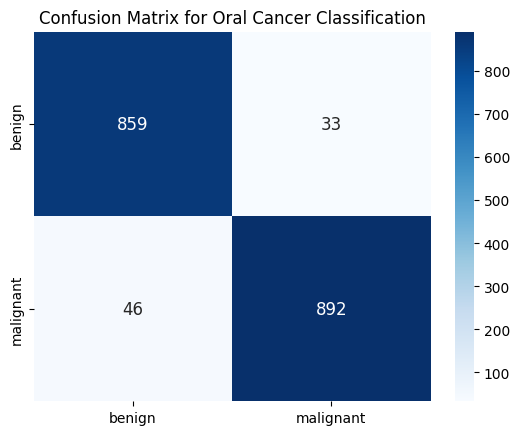

In [17]:
Cm = confusion_matrix(actual_label, pred)
ax = plt.axes()
sns.heatmap(Cm, cmap='Blues', annot=True,fmt="d",
            annot_kws={'size':12},
            xticklabels=labels,
            yticklabels=labels,
            ax=ax)

plt.title("Confusion Matrix for Oral Cancer Classification")
plt.show()